# Module 9 — Integrated capital allocation: run the whole module

**Final output:** `outputs/FINAL_M9_module_output.xlsx` (last cell).

**Order matters:** Module 9 reads the files Modules 1–8 saved; run them first (or use their saved outputs).

## Setup
Moves into the module folder so the paths below work, both locally and in Google Colab.

In [1]:
import os
import sys
from pathlib import Path

# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]
os.chdir(PROJECT_ROOT / "module_09_capital_allocation")                  # the paths below start from the module folder
print("Working folder:", Path.cwd().name)

Working folder: module_09_capital_allocation


## 0. Evidence check
Do all eight modules' Module 9 inputs exist?

In [2]:
%run helpers/m09_data.py

modules : 8
rows : 19
categories : ['Corporate lending (initiatives)', 'Digital banking (initiatives)', 'Digital banking (payments initiatives)', 'Risk management (analytics initiatives)', 'Retail lending (SME initiatives)', 'Wealth management (initiatives)', 'Retail lending', 'Corporate lending', 'Digital banking: cost of fraud risk', 'Wealth management: fees on client balances', 'Equity investments: ML stock selection (extra over holding all 15)', 'Equity investments (equal weight, 15 stocks)', 'High frequency trading: order timing (desk orders)', "High frequency trading: order timing on Module 9's equity money", 'High frequency trading: trading pilot', 'Derivatives hedging: protect equity money (100% floor put)', 'Derivatives hedging: protect equity money (90% floor put)', 'Derivatives hedging: protect equity money (80% floor put)', 'Derivatives hedging: the option book (choice C)']
Risk-free 6.800000000000001 | equities 15.6 (8.6, 22.6) | swing 19.4


## 1. The allocation
Runs `notebooks/m09_allocation.ipynb`: evidence, rules, financial decision framework, allocation, optimiser comparison, leverage sensitivity, stress tests, plan vs alternatives, what the ML adds, growth path, integration map, ML scorecard, governance, actions.

modules: 8
rows: 19
categories: ['Corporate lending (initiatives)', 'Digital banking (initiatives)', 'Digital banking (payments initiatives)', 'Risk management (analytics initiatives)', 'Retail lending (SME initiatives)', 'Wealth management (initiatives)', 'Retail lending', 'Corporate lending', 'Digital banking: cost of fraud risk', 'Wealth management: fees on client balances', 'Equity investments: ML stock selection (extra over holding all 15)', 'Equity investments (equal weight, 15 stocks)', 'High frequency trading: order timing (desk orders)', "High frequency trading: order timing on Module 9's equity money", 'High frequency trading: trading pilot', 'Derivatives hedging: protect equity money (100% floor put)', 'Derivatives hedging: protect equity money (90% floor put)', 'Derivatives hedging: protect equity money (80% floor put)', 'Derivatives hedging: the option book (choice C)']


,Module,Category,Return per ₹ deployed (% a year),Bad-year result per ₹ (% a year),Capacity (₹ crore),Evidence strength
0,1,Corporate lending (initiatives),6.3,-6.1,15.81,Weak: P(Success) model ROC-AUC 0.58; years 4–5 assumed equal to year 3
1,1,Digital banking (initiatives),13.2,-6.6,9.34,Weak: P(Success) model ROC-AUC 0.58; years 4–5 assumed equal to year 3
2,1,Digital banking (payments initiatives),13.0,-2.1,10.08,Weak: P(Success) model ROC-AUC 0.58; years 4–5 assumed equal to year 3
3,1,Risk management (analytics initiatives),10.4,-5.4,11.5,Weak: P(Success) model ROC-AUC 0.58; years 4–5 assumed equal to year 3
4,1,Retail lending (SME initiatives),13.3,-1.4,4.18,Weak: P(Success) model ROC-AUC 0.58; years 4–5 assumed equal to year 3
5,1,Wealth management (initiatives),17.6,3.6,15.28,Weak: P(Success) model ROC-AUC 0.58; years 4–5 assumed equal to year 3
6,2,Retail lending,3.3,-2.14,210.52,Strong: PD scorecard validated on unseen loans (Task 1–2)
7,2,Corporate lending,3.31,-2.19,75.42,Strong: PD scorecard validated on unseen loans (Task 1–2)
8,3,Digital banking: cost of fraud risk,-1.55,-4.03,Scales with the money moved,Strong: tested on unseen transactions; costs from the brief
9,4,Wealth management: fees on client balances,1.77,1.39,328.1,Medium: fee yield read from the CLV formula (exact fit); churn can't be pred...


Risk-free rate: 6.8% a year (Module 6)
Module 1 deployable initiatives by business unit:


,Initiatives,Fund now (₹ crore),Capacity (₹ crore),Expected return (% a year),1-in-20 bad case (% a year)
Business unit,,,,,
Corporate Banking,8,1.03,15.81,6.33,-6.13
Digital Banking,7,0.00,9.34,13.20,-6.64
Payments,7,0.00,10.08,13.00,-2.14
Risk Analytics,7,0.00,11.50,10.45,-5.35
SME Lending,2,0.00,4.18,13.34,-1.42
Wealth,9,2.21,15.28,17.59,3.57
All units,40,3.24,66.19,12.13,5.95


Module 2 lending:


,Group,Loan type,₹ lent (crore),Return per ₹ lent (% a year),Bad year: PD × 2 (% a year),"Severe year: PD × 2, LGD 60% (% a year)"
0,Approve,Retail,210.52,3.30,-2.14,-7.58
1,Approve,Corporate,75.42,3.31,-2.19,-7.68
2,Approve,All,285.94,3.30,-2.15,-7.61
3,Review,Retail,120.32,0.96,-7.88,-16.73
4,Review,Corporate,43.61,0.97,-7.68,-16.34
5,Review,All,163.93,0.96,-7.83,-16.62


Module 6 equities (equal weight): 15.6% a year (95% range 8.6–22.6%), real-market swing 19.4%, crash −20%
Module 8 puts on the equity holding (per ₹100 crore):


,Floor,Priced at,Cost a year (₹ crore per ₹100 crore),Normal year: equity return after the cost (% a year),Stocks -10%: result (₹ crore per ₹100 crore),Stocks -20%: result (₹ crore per ₹100 crore),Stocks -30%: result (₹ crore per ₹100 crore)
0,100%,Module 6 swing (19.4%),4.67,10.93,-4.67,-4.67,-4.67
1,100%,Check: puts priced dearer (25.0%),6.75,8.85,-6.75,-6.75,-6.75
2,90%,Module 6 swing (19.4%),1.81,13.79,-11.81,-11.81,-11.81
3,90%,Check: puts priced dearer (25.0%),3.33,12.27,-13.33,-13.33,-13.33
4,80%,Module 6 swing (19.4%),0.49,15.11,-10.49,-20.49,-20.49
5,80%,Check: puts priced dearer (25.0%),1.31,14.29,-11.31,-21.31,-21.31


,Use,Return (% a year),Bad year (% a year),Capacity (₹ crore),Source,Beats the 6.8% hurdle?,Return above hurdle per ₹ of bad-year loss
0,Initiatives: Corporate Banking,6.327,-6.125,15.810,Module 1,No,-0.077
1,Initiatives: Digital Banking,13.198,-6.640,9.343,Module 1,Yes,0.964
2,Initiatives: Payments,13.002,-2.140,10.083,Module 1,Yes,2.899
3,Initiatives: Risk Analytics,10.448,-5.354,11.500,Module 1,Yes,0.681
4,Initiatives: SME Lending,13.337,-1.424,4.176,Module 1,Yes,4.590
5,Initiatives: Wealth,17.592,3.566,15.276,Module 1,Yes,inf
6,"Equities, with the 90% put",13.789,-11.811,inf,"Modules 6, 8",Yes,0.592
7,"Equities, unprotected",15.600,-20.000,inf,Module 6,Yes,0.440
8,"Lending: approved loans, today's prices",3.300,-2.153,285.942,Module 2,No,-1.626
9,Lending: Review queue,0.963,-7.831,163.928,Module 2,No,-0.745


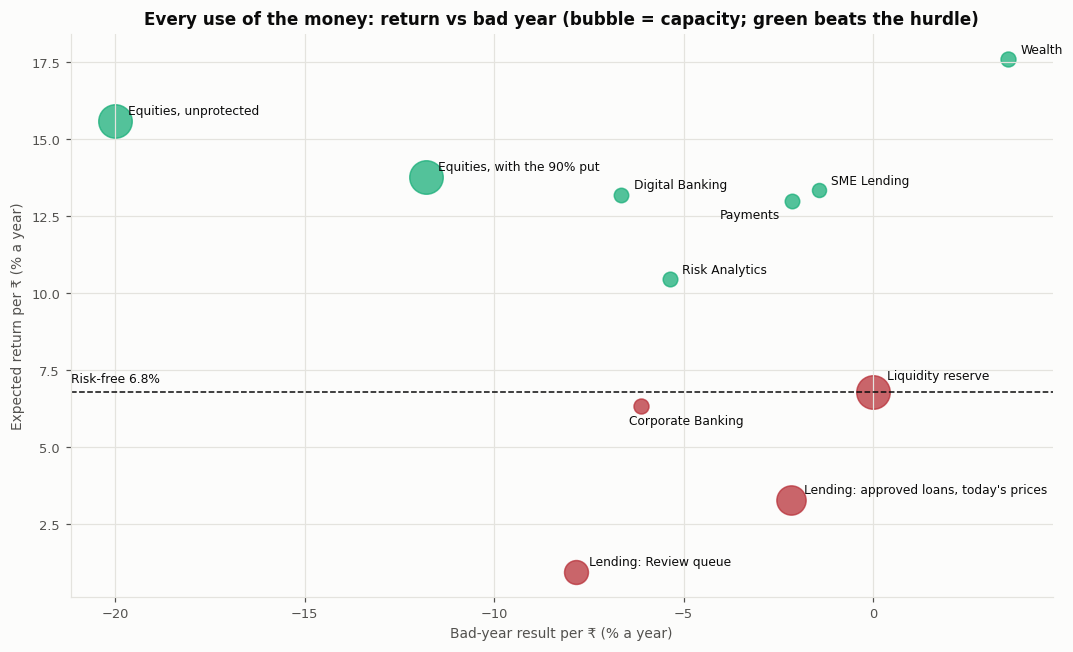

Bad-year budget ₹100 crore · cap 30% · reserve ≥ 10% · HFT ₹5 crore · lending pool ₹285.9 crore earmarked


,Module,1 Data,2 ML prediction,3 Financial metric in ₹,4 Risk,5 Decision rule,6 Control and owner
0,1 Corporate finance,180 initiatives,P(Success): lasso (weak; screens 36 slow payers into Reject),"NPV, Expected NPV, IRR by business unit","Payback, loss tolerance, 1-in-20 bad case",Fund / Review / Reject; return above 6.8%,Staged release; Head of Strategy
1,2 Credit risk,"5,000 loans",PD: lasso scorecard (calibrated),ECL = PD × 40% × loan; return per ₹ lent,PD × 2 recession; LGD 60%,Approve / Review / Reject; required rate,"PSI, defaults vs PD; Chief Risk Officer"
2,3 Fraud,"30,000 transactions",P(fraud): LightGBM,Cost of fraud risk per ₹ moved,Fraud × 3,Investigate above 4.76% (brief's costs),Weekly cost check; Fraud Operations
3,4 Customers,"5,000 customers",Churn: no model beats a coin flip beyond luck,CLV; fee yield 1.80%,"Market −20%, churn × 2",No model-driven retention spend,Randomised test first; Head of Wealth
4,5 Equity markets,"15 stocks, 43 test months",Returns: no model beats luck,Return vs holding all 15 (after costs in Module 6),Swing 10.9–13.2% for any top 5 vs 6.7% for all 15,No ML stock-picking,Revisit only with new data; CIO
5,6 Portfolio,Daily returns,Not ML (Markowitz vs equal weight),"Return 15.6%, Sharpe","VaR, CVaR, −20% crash",Equal weight,Monthly VaR limit; CIO
6,7 HFT,"Order book, 20 days",Direction: logistic regression,₹ saved per ₹1 crore of orders; profit after costs,Costs +1 bp,Time orders; pilot with stop rule,Daily savings; Head of Trading
7,8 Derivatives,"10,000 options",ML pricing loses to Black-Scholes,"BS value, Greeks, put cost",1-in-100 bad day; volatility −5,BS pricing; hedge C; 90% put on equities,Daily hedge limit; derivatives desk
8,9 Allocation,Modules 1–8 inputs,Uses every module's validated result,Return per ₹ deployed vs 6.8%,8 stress scenarios; ₹100 crore budget,Best uses first within limits,Quarterly ALCO review; CFO


,Order,Use,Score,₹ crore added,What limited it
0,1,Initiatives: Wealth,inf,13.067,capacity
1,2,Initiatives: SME Lending,4.590,4.176,capacity
2,3,Initiatives: Payments,2.899,10.083,capacity
3,4,Initiatives: Digital Banking,0.964,9.343,capacity
4,5,Initiatives: Risk Analytics,0.681,11.500,capacity
5,6,"Equities, with the 90% put",0.592,300.000,30% cap


Bad-year budget left: ₹62.5 crore of ₹100 crore (each use's own bad year added up, before counting the reserve's interest)


,Use,Category,₹ crore,Expected ₹ crore a year
0,Initiatives (Fund): Corporate Banking,Corporate lending,1.033,0.065
1,Initiatives (Fund): Wealth,Wealth management,2.208,0.389
2,HFT trading pilot,High frequency trading,5.000,0.000
3,Initiatives (Review): Wealth,Wealth management,13.067,2.299
4,Initiatives (Review): SME Lending,Retail lending,4.176,0.557
5,Initiatives (Review): Payments,Digital banking,10.083,1.311
6,Initiatives (Review): Digital Banking,Digital banking,9.343,1.233
7,Initiatives (Review): Risk Analytics,Derivatives hedging,11.500,1.202
8,"Equities, with the 90% put",Equity investments,300.000,46.831
9,Derivatives hedging: 90% put on the equities,Derivatives hedging,5.432,-5.432


,₹ crore,Expected ₹ crore a year,"Share of ₹1,000 crore",Expected return (% a year)
Category,,,,
Corporate lending,1.033,0.065,0.001,6.327
Retail lending,4.176,0.557,0.004,13.337
Digital banking,19.426,2.544,0.019,13.096
Wealth management,15.276,2.687,0.015,17.592
Equity investments,300.000,46.831,0.300,15.610
High frequency trading,5.000,0.000,0.005,0.000
Derivatives hedging,17.065,-4.236,0.017,-24.822
Liquidity reserve,638.025,43.386,0.638,6.800


Expected: ₹91.8 crore a year = 9.18% on ₹1,000 crore (risk-free alone: 6.8%); liquidity reserve ₹638.0 crore, of which ₹285.9 crore earmarked for re-priced lending


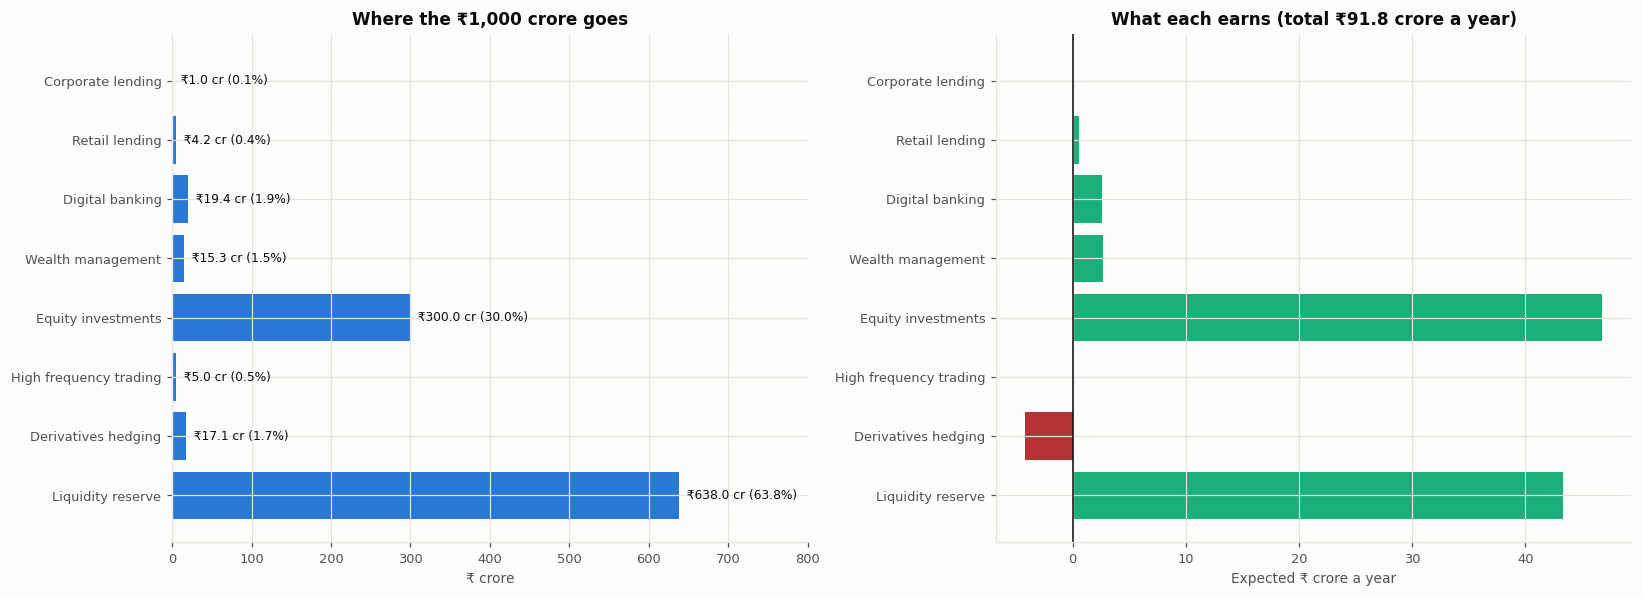

,Caution (λ),Initiatives (₹ crore),Equities with put (₹ crore),Lending (approved) (₹ crore),Liquidity reserve (₹ crore),Expected return (% a year),Yearly swing (%)
0,2,51.41,300.00,0.0,648.59,9.26,4.84
1,5,51.41,300.00,0.0,648.59,9.26,4.84
2,10,51.41,279.08,0.0,669.51,9.11,4.52
3,Method A (chosen),51.41,300.00,0.0,648.59,9.18,4.84


Reading: the optimiser lands on the same shape (initiatives to capacity, equities at or near the 30% cap, no lending, the rest in the reserve), so method A's split doesn't depend on the method; it depends on the evidence and the limits. In method A's row the reserve column also holds the ₹5 crore pilot and the ₹5.6 crore of hedging (put and option book).


,Cost of funds (% a year),"Return on capital, normal year (%)","Return on capital, recession year (%)"
0,2.0,12.8,-32.6
1,3.0,5.5,-39.9
2,4.0,-1.8,-47.3
3,5.0,-9.2,-54.6
4,6.0,-16.5,-61.9


Approved loans of ₹285.9 crore would tie up ₹34.3 crore of capital. Lending beats the 6.8% hurdle only if the cost of funds is below 2.82% and breaks even at 3.75%; a recession year loses 33% of the capital even at 2%. Leverage multiplies both the return and the bad year, and the answer rests on a number the data doesn't have: so the main view stays ₹1 = ₹1 (M9-07).


,Scenario,Year's result (₹ crore),Against plan (₹ crore),Within the ₹100 crore budget?,Note
0,Plan,91.81,0.00,Yes,
1,1. Market crash: all stocks −20% (the put pays),15.01,-76.80,Yes,
2,2. Equities at the low end of their range (8.6%),70.81,-21.00,Yes,
3,3. Initiatives disappoint (1-in-20 outcome),83.72,-8.08,Yes,
4,4. Interest rates fall: risk-free 6.8% → 5%,80.32,-11.48,Yes,
5,5. Credit recession (PD × 2) once the lending pool is released,66.21,-25.60,Yes,Approved loans released at today's prices; the plan re-prices them first (st...
6,"5b. Same, collateral fetches less (LGD 60%)",50.62,-41.19,Yes,Approved loans released at today's prices; the plan re-prices them first (st...
7,"6. Fraud three times as common (Digital banking, per ₹ moved)",91.81,0.00,Yes,Fraud cost per ₹ moved rises from 1.55% to 4.03% (Module 3); money moved isn...
8,7. HFT pilot: costs 1 bp higher (stop rule caps the loss),91.31,-0.50,Yes,
9,8. All at once: 1 + 3 + 4 + 7,-5.06,-96.87,Yes,


Reverse stress — with the put: equities can lose at most ₹35.4 crore (10% floor + cost), so no crash breaks the ₹100 crore budget. Without the put: a fall of 50% in a year would (the rest of the allocation earns ₹50.4 crore).


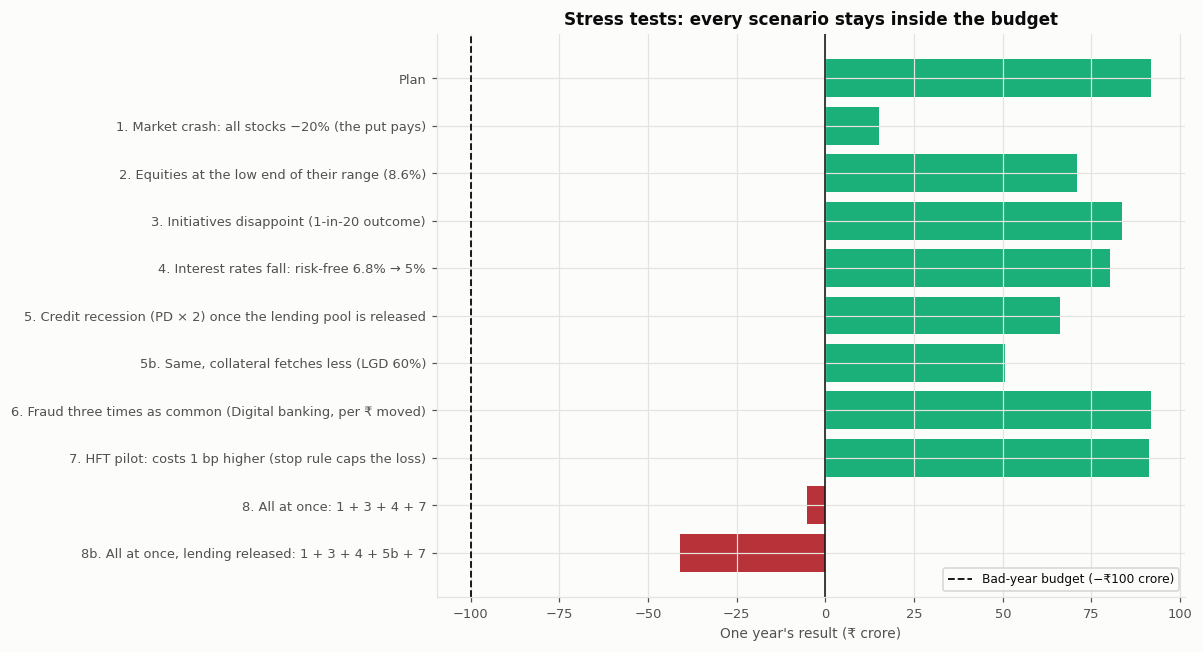

,₹ crore,Expected ₹ crore a year,"Share of ₹1,000 crore",Expected return (% a year),Evidence strength,How fast money comes back
Category,,,,,,
Corporate lending,1.033,0.065,0.001,6.327,Weak (Module 1 model ROC-AUC 0.58),Locked in about 5 years
Retail lending,4.176,0.557,0.004,13.337,Weak (Module 1 model ROC-AUC 0.58),Locked in about 5 years
Digital banking,19.426,2.544,0.019,13.096,Weak (Module 1); fraud control strong (Module 3),Locked in about 5 years
Wealth management,15.276,2.687,0.015,17.592,Weak (Module 1),Locked in about 5 years
Equity investments,300.000,46.831,0.300,15.610,Medium (43 test months; risk a stress estimate),Days
High frequency trading,5.000,0.000,0.005,0.000,Pilot (3 test days),Same day
Derivatives hedging,17.065,-4.236,0.017,-24.822,Weak for Risk Analytics (Module 1); medium for the put and hedge C,Risk Analytics: locked in about 5 years; put: spent each year; hedge C: days
Liquidity reserve,638.025,43.386,0.638,6.800,Strong (market rate),Days


₹ crore by evidence strength: {'Medium': 305.6, 'Pilot': 5.0, 'Strong': 638.0, 'Weak': 51.4}
₹ crore by how fast it comes back: {'back within days': 943.2, 'locked in for about 5 years': 51.4, 'spent each year (the put)': 5.4}


,"Way to deploy ₹1,000 crore",Profit a year (₹ crore),Money put into NovaFin's businesses (₹ crore),"Bad year, all at once (₹ crore)",Profit (% a year),Within the ₹100 crore bad-year budget?
0,The bank's way (status quo),-2.35,923.10,-74.27,-0.24,Yes
1,All in safe securities,68.00,0.00,50.00,6.80,Yes
2,"All in equities, unprotected",156.00,0.00,-200.00,15.60,No
3,Our plan (Year 1),91.83,56.41,-5.06,9.18,Yes


The bank's way earns −₹2.4 crore a year: its lending at today's prices earns 0.43% above expected losses and its initiatives -3.6% a year, so deploying more money that way lowers profit. Our plan earns ₹91.8 crore with a far smaller bad year.


,Module,Without the ML work,With it,₹ difference,₹ crore a year (where measurable)
0,2 Credit risk,Lend to every applicant at today's prices,Approve / Review / Reject by the PD scorecard,"+₹7.4 crore a year earned above actual losses, with ₹354 crore less lent at ...",7.38000
1,1 Corporate finance,Fund all 180 initiatives (₹283 crore),"Fund 2, review 38 in priority order, reject 140",+₹17.4 crore a year expected (the 33 the plan funds: 13.7% a year; all 180: ...,17.39756
2,3 Fraud,No screening,Investigate when P(fraud) > 4.76%,Saves ₹4.58 crore per ₹100 crore of money moved (6.13% → 1.55%),NaN
3,7 HFT,Orders placed without timing,Wait 0.1 s when the model expects an adverse move,₹3.43 crore a year per ₹100 crore of orders a day; ₹0.03 crore on the equity...,NaN
4,5–6 Equities,Follow the ML stock picks,Hold all 15 (the ML picks failed validation),"+₹15.0 crore a year on ₹300 crore (10.6% vs 15.6%; not beyond luck, p 0.39)",15.00000
5,8 Derivatives,Price options with ML; hedge with shares only,Black-Scholes pricing; hedge C (delta + half vega),"Avoids ₹1,500–₹24,000 of mispricing per 10,000 options; cuts the option book...",NaN
6,4 Customers,Spend on retention from a churn model,No churn model (it can't predict); randomised test first,Avoids spending on calls that a coin flip would target as well,NaN


Measurable: ₹39.8 crore a year against the same decisions without this work, before fraud and order-timing savings, which scale with NovaFin's volumes.


,Stage,Lending (₹ crore),Liquidity reserve (₹ crore),Profit a year (₹ crore),Money put into NovaFin's businesses (₹ crore),"Bad year, all at once (₹ crore)","Profit (% a year on ₹1,000 crore)"
0,Year 1 (now),0.00,638.03,91.83,56.41,-5.06,9.18
1,"Year 2, ₹1 = ₹1 view",449.87,188.16,91.83,506.28,-26.97,9.18
2,"Year 2, bank view (12% capital, 5% cost of funds)",449.87,584.04,98.96,506.28,-26.97,9.90


Re-pricing needed: approved loans about 12.25% a year (today 8.75%); Review loans about 15.59% (today 9.76%). Year 2 grows NovaFin's loan book by ₹450 crore; in the bank view lending ties up only ₹54 crore of capital and profit rises to ₹99.0 crore a year. Risk: higher rates may drive good borrowers away (the PDs assume the same borrowers), so the release is staged and tested each quarter.


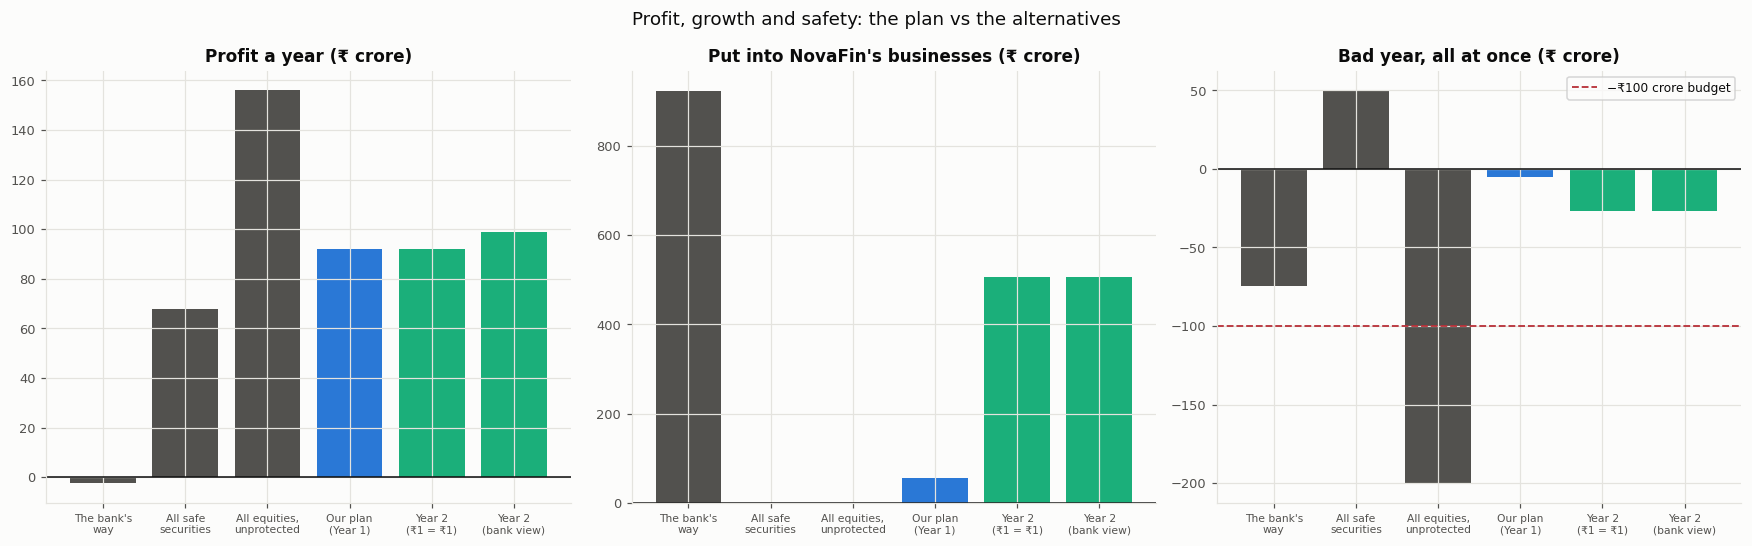

,Link,What passes,How it is used,₹ effect
0,Module 5 → Module 6,No model predicts returns beyond luck,Module 6 holds all 15 at equal weight instead of ML picks,"+₹15.0 crore a year on ₹300 crore (not beyond luck, p 0.39)"
1,Module 6 → Module 8,Equities' real-market swing (19.4%) and crash loss (−20%),Module 8 prices the put that protects Module 9's equities,Crash loss ₹60 crore → ₹35.4 crore for ₹5.4 crore a year
2,Module 6 → Module 7,Equity turnover (≈ 0.8× a year),Order timing applied to the equity book's own trades,₹0.03 crore a year
3,"Module 1 → Modules 3, 4",Return per ₹ of capital by business unit,Gives Digital banking and Wealth a return per ₹ of capital (no other data ha...,"Digital 13.2%, Payments 13.0%, Wealth 17.6% a year"
4,Module 3 → Digital banking money,Fraud cost 1.55% of money moved with the rule (6.13% without),Digital banking initiatives are funded only while the rule runs,Saves ₹4.58 crore per ₹100 crore moved
5,Module 2 → Module 9 lending pool,Approved loans earn 3.3%; re-pricing needs about 12.3%,Lending waits in an earmarked pool; released when re-priced (growth path),₹450 crore of loan growth in Year 2
6,Module 2 → stress tests,PD × 2 recession: −2.15% per ₹ lent,Scenario 5 of the allocation's stress test,−₹6.2 crore if the pool were lent in a recession
7,Module 8 → governance,Hedge C cuts the option book's 1-in-100 bad day by 45%; delta-only is worse ...,Hedging rule and trigger in the governance table,1-in-100 bad day ≤ 4% of the book
8,Modules 1–8 → Module 9,"The same fields from every module (return, bad year, capacity, evidence)","One ranking across all businesses, best uses first",₹91.8 crore a year vs −₹2.4 crore the bank's way


,Module,Predicts,Models compared (and benchmark),Result on unseen data,Verdict,Validation,Explained by,Used in the allocation?
0,1 Corporate finance,P(Success),"Lasso vs logistic, tree, forest, boosting; benchmark = historical success rate",ROC-AUC 0.578 ± 0.08; luck p 0.17,Not beyond luck on ranking; its flag separates failures (30% vs 14%),Repeated cross-validation; shuffled labels,Odds ratios,Screens 36 slow payers into Reject; the rating alone gives a similar list
1,2 Credit risk,PD (default),"Lasso vs logistic, tree, forest, LightGBM; benchmark = the bank's own intere...",ROC-AUC 0.731 vs 0.702 for the bank's rate (cross-validation); 0.741 vs 0.71...,Won all 25 cross-validation rounds; on the test loans alone not proven at 95...,Cross-validation + held-out test; calibration tests; trees ruled out for ove...,Odds ratios; a reason per loan,Yes: lending decisions
2,3 Fraud,P(fraud),"Logistic, lasso, tree, forest, LightGBM; benchmark = amount alone","PR-AUC 0.132 vs 0.116, ROC-AUC 0.794 vs 0.788 (cross-validation); 0.124 vs 0...",ROC-AUC gain proven on the test; PR-AUC gain just touches zero. Cuts the cos...,Cross-validation + time-ordered test; costs from the brief,Reasons in words per transaction,Yes: condition for Digital banking
3,4 Customers,Churn,"Logistic, tree, forest, LightGBM (+ a 115-input search)",ROC-AUC 0.490 (coin flip 0.5); luck p 0.83,No model beats a coin flip beyond luck,Shuffled labels; Bonferroni line,—,No (randomised test first)
4,5 Equity markets,Next-month return,"Linear, ridge, forest, LightGBM; benchmark = holding all 15",Ridge IC 0.004; best top-5 p ≥ 0.40,No model beats luck,"Walk-forward, 43 months; shuffled returns",—,No (hold all 15)
5,7 HFT,Next 0.1 s direction,"Logistic, forest, LightGBM; benchmark = order-book imbalance alone",AUC 0.791 vs 0.781 (DeLong p < 0.0001); luck p 0.0099,Beats the benchmark beyond luck; overfitting gap +0.003,Separate tuning and test days; DeLong; shuffled labels,Buyer/seller balance in plain words,Yes: order timing; pilot
6,8 Derivatives,Option price,Direct ML and hybrid × 4 models; benchmark = Black-Scholes,Average gap BS ₹6.07 vs best ML ₹6.22,ML worse than Black-Scholes in all 12 groups and 13 of 15 stocks,Held-out options; paired 95% ranges; shuffled corrections,Greeks,No (Black-Scholes)


Reproducibility: every notebook uses seed 42; each module's runner gives the same files as its standalone notebooks (checked file by file on the project's computer).


,Use,₹ crore,Expected ₹ crore a year,Bad-year result (₹ crore),Why,Owner,First action and when,How we know it is working
0,"Equities: all 15 stocks, equal weight, with a 1-year 90% put",305.43,41.40,-35.43,The only large use above 6.8% (15.6% a year; 13.8% after the put). Held at t...,Chief Investment Officer,"Month 1: buy, and buy the put",VaR within limit every month; put renewed every year
1,"Initiatives ready now: 1075 Wealth in full, 1062 Corporate Banking in stages",3.24,0.45,0.02,Module 1's two Fund projects: positive Expected NPV and within loss tolerance,Head of Strategy,Now,Milestones met on time and on budget
2,"Initiatives after review: Wealth, Payments, Digital Banking, Risk Analytics,...",48.17,6.60,-1.05,Units whose initiatives return above 6.8% a year; each project still needs a...,Head of Strategy (+ Head of Fraud Operations for Digital),"Quarters 1–2: review unit by unit, release in stages",Each released project passes review; milestones met
3,HFT trading pilot with a stop rule,5.00,0.00,-0.50,Order timing saves money on existing orders with no capital; trading itself ...,Head of Trading,Now; decide after 1 quarter,Pilot net profit above 0 after costs; stop at the loss limit
4,Option book hedge (choice C: delta + half vega),0.13,-0.01,0.00,Cuts the option book's 1-in-100 bad day by 45%,Derivatives desk,"Now, reset daily",1-in-100 bad day ≤ 4% of the book
5,Liquidity reserve: government securities (released by the plan below),638.03,43.39,31.90,Earns 6.8% safely while each use waits for its release test; available withi...,Treasurer with ALCO,Now,Released only by the tests in the release plan


,Step,Release,₹ crore,What it funds,Released when (the test),Checked,Owner,If the test fails,Cost of releasing it now at today's prices (₹ crore a year)
0,1,"Approved loans, re-priced",285.94,Loans the scorecard approves (8.75% today),Re-priced approved loans earn at least 6.8% a year after expected loss (rate...,Every quarter,Chief Risk Officer + Head of Lending; ALCO releases,"The money stays in the reserve, earning 6.8%",10.01
1,2,"Review loans, fixed",163.93,"Loans the scorecard sends to review (re-price, add collateral, or a person c...","The same test, at a rate of about 15.6% (or the risk cut by collateral or a ...","Every quarter, after step 1",Chief Risk Officer + Head of Lending; ALCO releases,"The money stays in the reserve, earning 6.8%",9.57
2,3,Future initiatives,88.16,New initiatives from the next pipeline (and any business that later beats 6.8%),"Each project passes Module 1's rules: Expected NPV above 0, return above 6.8...",At each project review,Head of Strategy; CFO approves,Not funded; the money stays in the reserve,NaN
3,Floor,"Minimum reserve, never released",100.00,Cash for withdrawals and a bad year,"Not released: at least 10% of the ₹1,000 crore stays safe",Every quarter,Treasurer with ALCO,—,NaN


,Stage,When,Liquidity reserve (₹ crore),Loan book (₹ crore),Initiatives and pilot (₹ crore),Money working in NovaFin's businesses (₹ crore),Profit a year (₹ crore),"Profit a year, bank view (₹ crore)","Bad year, all at once (₹ crore)",Share of the ₹100 crore bad-year budget used,"Bad year if collateral also fetches less, LGD 60% (₹ crore)",Profit above the bank's way (₹ crore a year),Bad year smaller than the bank's way by (₹ crore)
0,Today (Year 1),Now,638.03,0.00,56.41,56.41,91.83,91.83,-5.06,0.05,-5.06,94.19,69.21
1,After step 1: approved loans re-priced,Once the quarterly test passes (planned in Year 2),352.08,285.94,56.41,342.35,91.83,96.36,-15.50,0.16,-31.10,94.19,58.77
2,After step 2: Review loans fixed,Year 2,188.16,449.87,56.41,506.28,91.83,98.96,-26.97,0.27,-56.97,94.19,47.30
3,After step 3: future initiatives (if like today's),As projects pass review,100.00,449.87,144.57,594.44,97.94,105.06,-33.14,0.33,-63.15,100.29,41.13


The reserve is a waiting room, not idle money: it earns ₹43.4 crore a year, and ₹538 crore of it moves into lending and initiatives as each test is passed; only the ₹100 crore floor stays. Releasing the ₹450 crore of loans today, at today's prices, would cost ₹19.6 crore a year against the reserve.


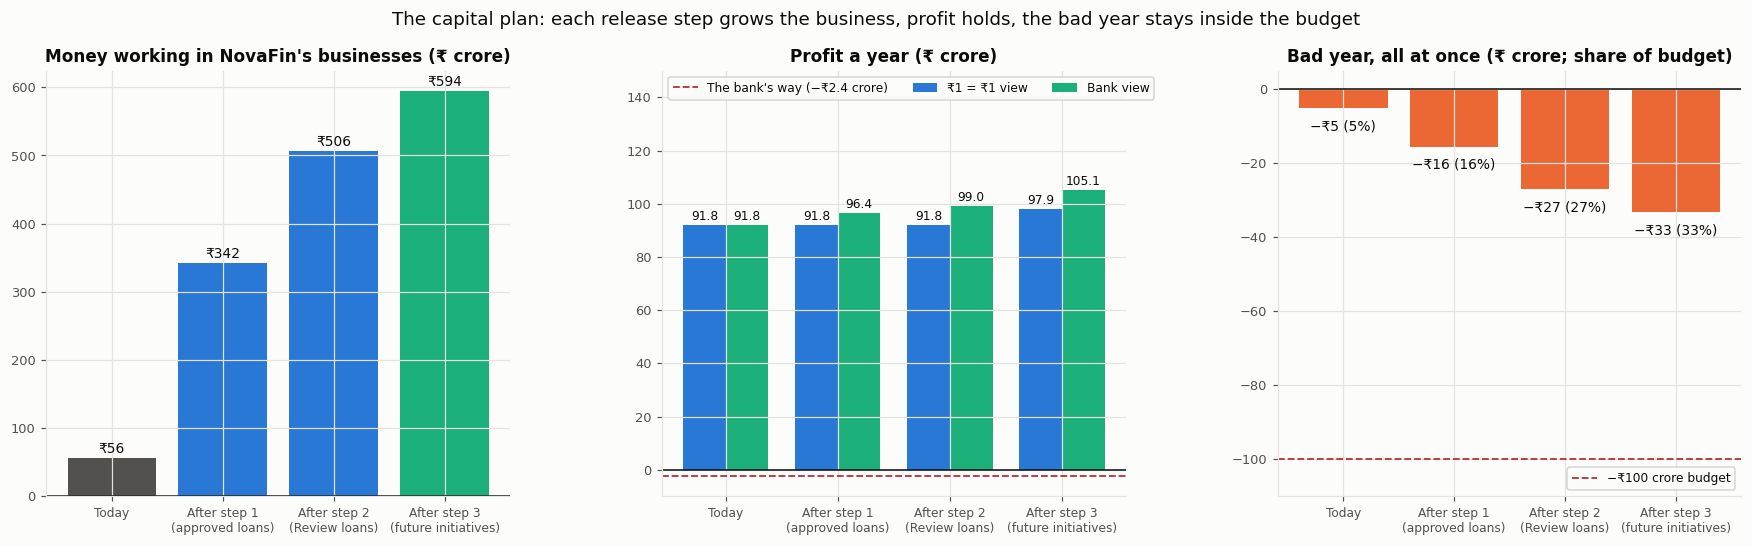

,Model or control,Used for,Owner,What is watched,Trigger → action,How it is explained
0,PD scorecard (Module 2),Lending decisions; the lending-pool release test,Chief Risk Officer (credit),"Monthly: score drift (PSI), defaults by band vs PD",PSI > 0.25 or defaults > 1.5 × PD in a band → re-fit; release the pool only ...,Odds ratios; a reason for every loan
1,Fraud model and 4.76% line (Module 3),Condition for Digital banking money,Head of Fraud Operations,"Weekly: fraud caught, false alarms, cost per ₹ moved",Cost > 2% of money moved → review the line; investigations above capacity → ...,Reasons in words per transaction
2,P(Success) model (Module 1),Screens slow payers only (weak: ROC-AUC 0.58),Head of Strategy,Success of funded initiatives vs predicted,"Review money released only after human review, in stages at milestones",Odds ratios; every check per initiative
3,Order-timing model (Module 7),Desk order timing; the HFT pilot,Head of Trading,Daily saving per ₹1 crore of orders; pilot profit after costs,Savings negative 5 days running → switch off; pilot stops if net profit < 0,Buyer/seller balance in plain words
4,"No model, by evidence (Modules 4, 5, 6, 8)","Stock-picking, option pricing, churn targeting","Investments, derivatives, wealth heads",—,Revisit only with new data; churn needs a randomised test before any spend,Results tables in each module
5,"Equity limit and 90% put (Modules 6, 8)",₹300 crore cap; crash protection,Chief Investment Officer,Monthly VaR (₹8 crore per ₹100 crore a month); the put's floor,VaR above limit → cut back to the cap; renew the put every year,Scenario table
6,Option-book hedge C (Module 8),Volatility and stock risk of the option book,Derivatives desk,Daily: 1-in-100 bad day ≤ 4% of the book,Above the limit → resize the hedge,Hedging-choice table
7,The allocation (Module 9),"₹1,000 crore",CFO with the asset–liability committee (ALCO),"Quarterly: stress tests, budget used, pool release test",Any scenario losing more than ₹100 crore → move money toward the reserve,Allocation and stress tables


,#,Phase,Action,Owner,When,₹ effect,How we know it worked
0,1,Now,Approve the allocation and the reserve release plan,Board,This meeting,₹91.8 crore a year expected (9.2%) vs ₹68 crore all in safe securities; wors...,Plan approved; every owner below named
1,2,Now,"Fund the two ready projects: 1075 (Wealth) in full, 1062 (Corporate Banking)...",Head of Strategy,Now,₹3.2 crore,Milestones met on time and on budget
2,3,Now,Run the order-timing model on the desk's and the equity book's orders; start...,Head of Trading,Now; continue or stop the pilot after 1 quarter,"Saves ₹1,315 per ₹1 crore of orders; pilot loss capped at ₹0.5 crore","Savings stay positive; pilot net profit above 0 after costs, otherwise it stops"
3,4,Now,Make the ML fraud rule the condition for Digital banking money; staff the in...,Head of Fraud Operations,Before any Digital banking release,Cost of fraud risk 1.55% of money moved vs 6.13% unscreened,Cost of fraud risk stays at or below 2% of money moved
4,5,Now,"Hedge the option book with choice C (delta + half vega), reset daily",Derivatives desk,Now,Cuts the option book's 1-in-100 bad day by 45%,1-in-100 bad day at or below 4% of the book
5,6,Month 1,"Buy ₹300 crore of equities (all 15, equal weight) with a 1-year 90% put",Chief Investment Officer,Within a month,+₹46.8 crore a year expected; the put costs ₹5.4 crore and caps a 20% crash ...,VaR within its limit every month; put renewed every year
6,7,Quarter 1,"Re-price the loan book by scorecard band, Retail first: approved loans about...",Chief Risk Officer + Head of Lending,Within a quarter,Prepares ₹450 crore of lending; lending it at today's prices would cost ₹19....,Re-priced loans earn at least 6.8% after expected loss; good borrowers are kept
7,8,Quarter 1,"Set up the model inventory, owners and triggers (the governance table); firs...",Chief Risk Officer,Within a quarter,Model risk controlled,Inventory live; every trigger has an owner
8,9,Quarters 1–2,"Review and release the initiative units that beat 6.8% (Wealth, Payments, Di...",Head of Strategy,Over 2 quarters,₹48.2 crore at about 13.7% a year,Each released project passes review; milestones met
9,10,Every quarter,Release step 1: ₹286 crore from the reserve into re-priced approved loans on...,ALCO (Chief Risk Officer + Head of Lending),Quarterly test; planned in Year 2,Loan book +₹286 crore; money working in the businesses ₹342 crore; profit ≥ ...,"Test passed; combined bad year −₹15.5 crore, inside the ₹100 crore budget"


,Category,₹ crore,"Share of ₹1,000 crore",Expected return (% a year),Bad-year result (₹ crore)
0,Corporate lending,1.03,0.0010,6.33,-0.06
1,Retail lending,4.18,0.0042,13.34,-0.06
2,Digital banking,19.43,0.0194,13.10,-0.84
3,Wealth management,15.28,0.0153,17.59,0.54
4,Equity investments,300.00,0.3000,15.61,-30.00
5,High frequency trading,5.00,0.0050,0.00,-0.50
6,Derivatives hedging,17.06,0.0171,-24.82,-6.05
7,Liquidity reserve,638.03,0.6380,6.80,31.90


Saved to module_09_capital_allocation/outputs
['01_uses_return_vs_bad_year.png', '02_allocation.png', '03_stress_tests.png', '04_plan_vs_alternatives.png', '05_capital_plan.png', 'FINAL_M9_allocation.csv', 'FINAL_M9_module_output.xlsx', 'actions.csv', 'allocation_lines.csv', 'allocation_steps.csv', 'capital_plan_stages.csv', 'capital_plan_use_now.csv', 'evidence_all_modules.csv', 'financial_decision_framework.csv', 'governance.csv', 'growth_path.csv', 'integration_map.csv', 'key_numbers.json', 'lending_leverage_sensitivity.csv', 'ml_scorecard.csv', 'ml_value_by_module.csv', 'optimiser_comparison.csv', 'plan_vs_alternatives.csv', 'reserve_release_plan.csv', 'stress_tests.csv', 'uses_compared.csv']


In [3]:
%run notebooks/m09_allocation.ipynb

## Final output workbook
Builds **`outputs/FINAL_M9_module_output.xlsx`**.

In [4]:
%run helpers/m09_final_output.py

Saved: FINAL_M9_module_output.xlsx
                                        Figure                                                                                                                                                                                 Value                Unit
             Expected profit of the allocation                                                                                                                                                                                  91.8      ₹ crore a year
The bank's way (status quo), same ₹1,000 crore                                                                                                                                                                                  -2.4      ₹ crore a year
                                      Equities                                                                                                                                                                            